Counts: pre points = 23 | post points = 729 | front_pre = 4 | front_post = 13


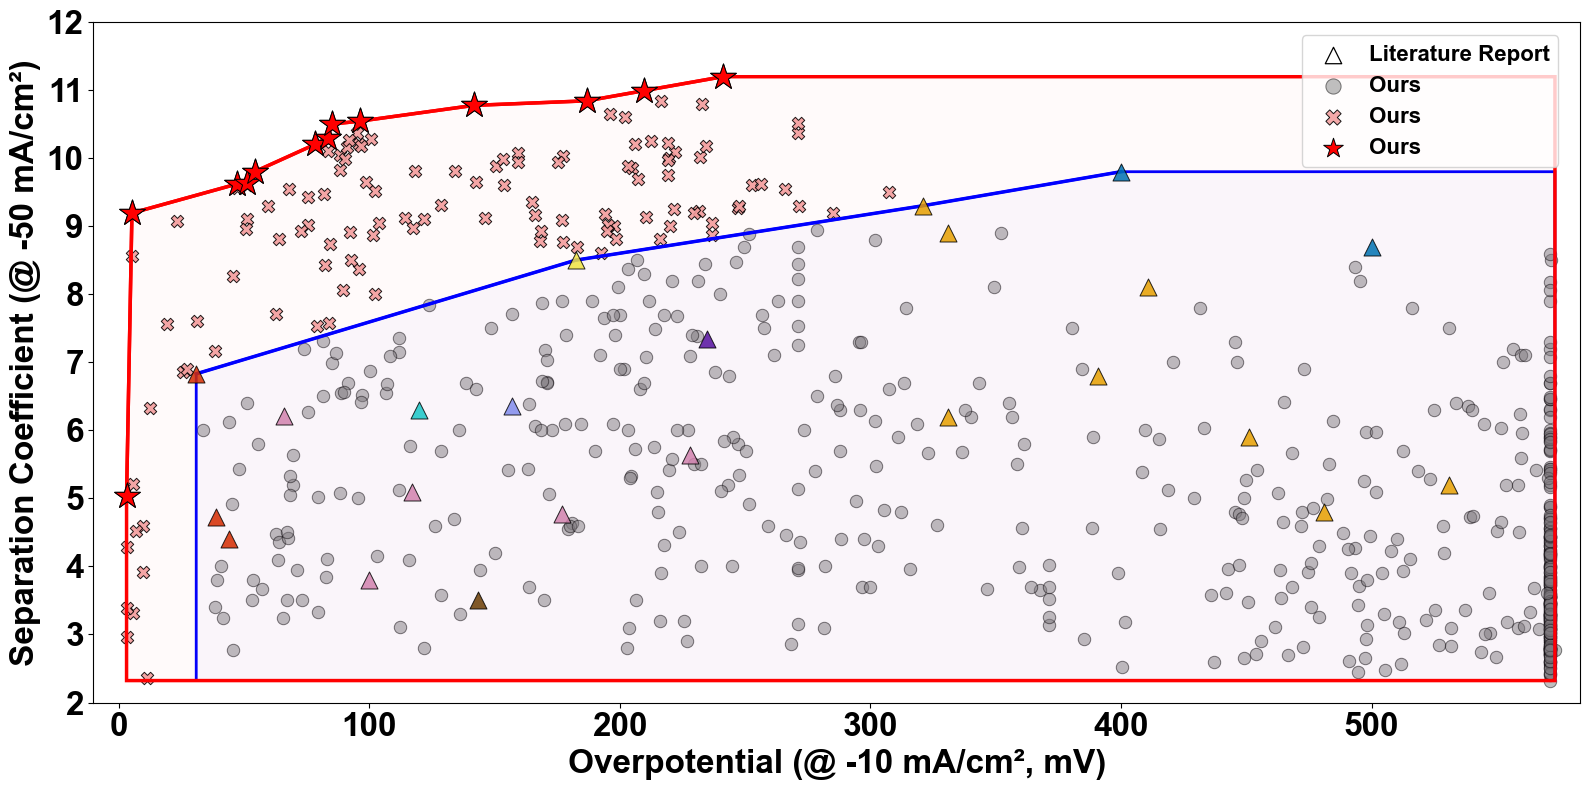

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon
from matplotlib.colors import to_rgba
from matplotlib.path import Path
import matplotlib as mpl

import re

def legend_name(lbl: str) -> str:
    lbl = str(lbl).strip()

    # Any literature reference -> same legend entry
    if re.match(r"^Reference\s+\d+$", lbl):
        return "Literature Report"

    if lbl.lower() == "ni foam":
        return "Ni Foam"
    if lbl.lower() == "pt sheet":
        return "Pt Sheet"

    return lbl


mpl.rcParams["path.simplify"] = False
# =========================
# 1) Load your Excel
# =========================
path = "all_data_corrected_v2.xlsx"   # <- change if needed
raw = pd.read_excel(path, sheet_name="Sheet1")

# Make ALL column names strings so "24"/"26"... match
raw.columns = raw.columns.map(lambda c: str(c).strip())

# first row repeats headers ("Overpotential / Separation Coefficient"), drop it
df = raw.iloc[1:].copy()

def to_num(s):
    return pd.to_numeric(s, errors="coerce")

# =========================
# 2) Map each dataset to (x,y) columns
# =========================
datasets = [
    ("This work", "Unnamed: 1"),
    ("24", "Unnamed: 3"),
    ("26", "Unnamed: 5"),
    ("25", "Unnamed: 7"),
    ("27", "Unnamed: 9"),
    ("23", "Unnamed: 11"),
    ("20", "Unnamed: 13"),
    ("22", "Unnamed: 15"),
    ("Ni foam", "Unnamed: 17"),
    ("Pt sheet", "Unnamed: 19"),
]

rows = []
for x_col, y_col in datasets:
    if x_col not in df.columns or y_col not in df.columns:
        print(f"[WARN] Missing columns: {x_col} / {y_col}")
        continue
    x = to_num(df[x_col])
    y = to_num(df[y_col])
    tmp = pd.DataFrame({"label": x_col, "x": x, "y": y}).dropna()
    rows.append(tmp)

data = pd.concat(rows, ignore_index=True)
data = data[np.isfinite(data["x"]) & np.isfinite(data["y"])].copy()
data = data.reset_index(drop=True)
data["pid"] = data.index   # <-- add this

# Rename numeric refs -> "Reference 24" etc.
data["label"] = data["label"].astype(str).str.strip()
data["label"] = data["label"].apply(lambda s: f"Reference {s}" if s.isdigit() else s)

# =========================
# Apply transformation to "This work" overpotential (x-values)
# =========================
is_this = data["label"].str.strip().str.lower().eq("this work")
thisw = data[is_this].copy()

# Apply the transformations: 1. Minus, 2. Clip at 0, 3. Multiply by 1000
thisw["x"] = -(thisw["x"]) * 1000

# Replace the transformed "This work" data back into the main dataframe
data.loc[is_this, "x"] = thisw["x"]

# =========================
# 3) Pareto frontier (X lower better, Y higher better)
# =========================
def pareto_frontier_xy(pts: pd.DataFrame) -> pd.DataFrame:
    s = pts.sort_values(["x", "y"], ascending=[True, False]).reset_index(drop=True)
    best_y = -np.inf
    keep = []
    for _, r in s.iterrows():
        if r["y"] > best_y:
            keep.append(True)
            best_y = r["y"]
        else:
            keep.append(False)
    return s.loc[keep].reset_index(drop=True)

import re

def legend_name(lbl: str) -> str:
    lbl = str(lbl).strip()

    # "Reference 20" -> "[20]"
    m = re.match(r"^Reference\s+(\d+)$", lbl)
    if m:
        return f"Literature Report"

    # Case fixes
    if lbl.lower() == "ni foam":
        return "Ni Foam"
    if lbl.lower() == "pt sheet":
        return "Pt Sheet"
    if lbl.lower() == "this work":
        return "Ours"

    return lbl


is_this = data["label"].str.strip().str.lower().eq("this work")

pre  = data[~is_this].copy()   # without This work
post = data.copy()             # with This work


front_pre  = pareto_frontier_xy(pre)
front_post = pareto_frontier_xy(post)

pareto_ids = set(front_post["pid"])   # <-- add this


print("Counts:",
      "pre points =", len(pre),
      "| post points =", len(post),
      "| front_pre =", len(front_pre),
      "| front_post =", len(front_post))

# =========================
# 4) Enclosure polygon (single outline, not stepwise)
# =========================
x_max = float(data["x"].max())
y_min = float(data["y"].min())
y_max = float(data["y"].max())

x_ref = x_max * 1.00 + 1e-6
y_ref = y_min - 1e-6

def enclosure_polygon(front: pd.DataFrame, x_ref: float, y_ref: float):
    f = front.sort_values("x", ascending=True).reset_index(drop=True)
    x0, y0 = float(f.loc[0, "x"]), float(f.loc[0, "y"])
    y_last = float(f.loc[len(f) - 1, "y"])
    pts = (
        [(x0, y_ref), (x0, y0)]
        + list(map(tuple, f[["x", "y"]].iloc[1:].to_numpy()))
        + [(x_ref, y_last), (x_ref, y_ref)]
    )
    return pts

poly_pre  = enclosure_polygon(front_pre,  x_ref, y_ref)
poly_post = enclosure_polygon(front_post, x_ref, y_ref)

# =========================
# 5) Plot
# =========================
fig, ax = plt.subplots(figsize=(16, 8))

def label_sort_key(lbl: str):
    lbl = str(lbl)
    if lbl.startswith("Reference "):
        try:
            return (0, int(lbl.split()[-1]))
        except:
            return (0, 10**9)
    if lbl == "Ni foam":  return (1, 0)
    if lbl == "Pt sheet": return (1, 1)
    return (2, lbl)

other_labels = sorted(pre["label"].unique(), key=label_sort_key)

# Bright palette (no gray)
# Light / pastel palette (no green)
palette = [
    "#0072B2",  # blue
    "#E69F00",  # orange
    "#5510A0",  # purple
    "#D52B00",  # vermillion
    "#F0E442",  # yellow
    "#D182AE",  # magenta
    "#818CEC",  # magenta
    "#6B3C03",  # brown
    "#19C7C7",  # blue
]

markers = ["*"]

# If you use this option, I'd recommend Option 1 instead since it avoids green/gray better.
markers = ["^"]

style = {}
for i, lbl in enumerate(other_labels):
    style[lbl] = dict(marker=markers[i % len(markers)],
                      color=palette[i % len(palette)])

# Enclosures (low zorder so they don't cover lines/points)
c_pre  = "blue"
c_post = "red"
ax.add_patch(Polygon(poly_pre, closed=True,
                     facecolor=to_rgba(c_pre, 0.02),
                     edgecolor=to_rgba(c_pre, 1.0),
                     linewidth=2.0,
                     zorder=1))
ax.add_patch(Polygon(poly_post, closed=True,
                     facecolor=to_rgba(c_post, 0.02),
                     edgecolor=to_rgba(c_post, 1.0),
                     linewidth=2.5,
                     zorder=1))

pre_plot = pre[~pre["pid"].isin(pareto_ids)]  # <-- exclude Pareto points

lit_legend_added = False  # <-- add this before the loop

for lbl in other_labels:
    sub = pre_plot[pre_plot["label"] == lbl]
    ax.scatter(
        sub["x"], sub["y"],
        s=150, alpha=0.85,
        label="_nolegend_",
        zorder=4, **style[lbl],
        edgecolors="black", linewidths=0.7,
    )


# ---- FIXED (2): classify "This work" by being INSIDE the PRE enclosure polygon ----
thisw = data[is_this].copy()
thisw_plot = thisw[~thisw["pid"].isin(pareto_ids)]  # <-- exclude Pareto points

pre_path = Path(poly_pre)
inside_pre = pre_path.contains_points(thisw_plot[["x", "y"]].to_numpy(), radius=1e-9)

ax.scatter(thisw_plot.loc[inside_pre, "x"], thisw_plot.loc[inside_pre, "y"],
           marker="o", s=80, color="gray", alpha=0.5,edgecolors="black", linewidths=0.7,
           label="Ours", zorder=0)

ax.scatter(thisw_plot.loc[~inside_pre, "x"], thisw_plot.loc[~inside_pre, "y"],
           marker="X", s=80, color="#F3A0A0", alpha=0.9,edgecolors="black", linewidths=0.7,
           label="Ours", zorder=0)

ax.scatter(front_post["x"], front_post["y"],
           marker="*", s=380, color="red",
           edgecolors="black", linewidths=0.7, zorder=10,
           label="Ours")



# Pareto front lines
ax.plot(front_post["x"], front_post["y"], color=c_post, linewidth=2.5, zorder=2)
ax.plot(front_pre["x"], front_pre["y"], color=c_pre, linewidth=2.5, zorder=2)

# ---- (1) highlight ALL-DATA pareto-front points with red stars ----
ax.scatter(front_post["x"], front_post["y"],
           marker="*", s=380, color="red",
           edgecolors="black", linewidths=0.7, zorder=10)

ax.set_ylabel("Separation Coefficient (@ -50 mA/cm²)", fontname="Arial", fontweight="bold", fontsize = 24)
ax.set_xlabel("Overpotential (@ -10 mA/cm², mV)", fontname="Arial", fontweight="bold", fontsize = 24)
from matplotlib.ticker import MultipleLocator

ax.yaxis.set_major_locator(MultipleLocator(1))  # ticks every 1 unit
# ax.xaxis.set_major_locator(MultipleLocator(200))  # ticks every 1 unit

ax.tick_params(axis="both", which="both", labelsize=24)  # optional sizing
for t in ax.get_xticklabels() + ax.get_yticklabels():
    t.set_fontname("Arial")
    t.set_fontweight("bold")
    
ax.set_xlim(-10, x_ref + 10)
ax.set_ylim(2, 12)

# ---- Force legend: Literature(^) + 3 entries for Ours, at upper-right ----
old_leg = ax.get_legend()
if old_leg is not None:
    old_leg.remove()

# Literature (triangle): black edge + white fill
h_lit = ax.scatter(
    [], [], marker="^", s=140,
    facecolors="white", edgecolors="black",
    linewidths=0.9, label="Literature Report"
)

# Ours (3 dummy handles)
h_inside = ax.scatter(
    [], [], marker="o", s=120,
    color="gray", alpha=0.5,
    edgecolors="black", linewidths=0.7,
    label="Ours"
)
h_outside = ax.scatter(
    [], [], marker="X", s=120,
    color="#F3A0A0", alpha=0.9,
    edgecolors="black", linewidths=0.7,
    label="Ours"
)
h_pareto = ax.scatter(
    [], [], marker="*", s=220,
    color="red", alpha=1.0,
    edgecolors="black", linewidths=0.7,
    label="Ours"
)

leg = ax.legend(
    handles=[h_lit, h_inside, h_outside, h_pareto],
    loc="upper right",
    bbox_to_anchor=(0.99, 0.99),
    frameon=True,
    prop={"family": "Arial", "weight": "bold", "size": 16},
    handletextpad=0.6,
    borderaxespad=0.3,
)


plt.tight_layout()
fig.savefig("pareto_plot_v2.png", dpi=300)
plt.show()

统计： pre 点数 = 23 | post 点数 = 729 | front_pre = 4 | front_post = 13


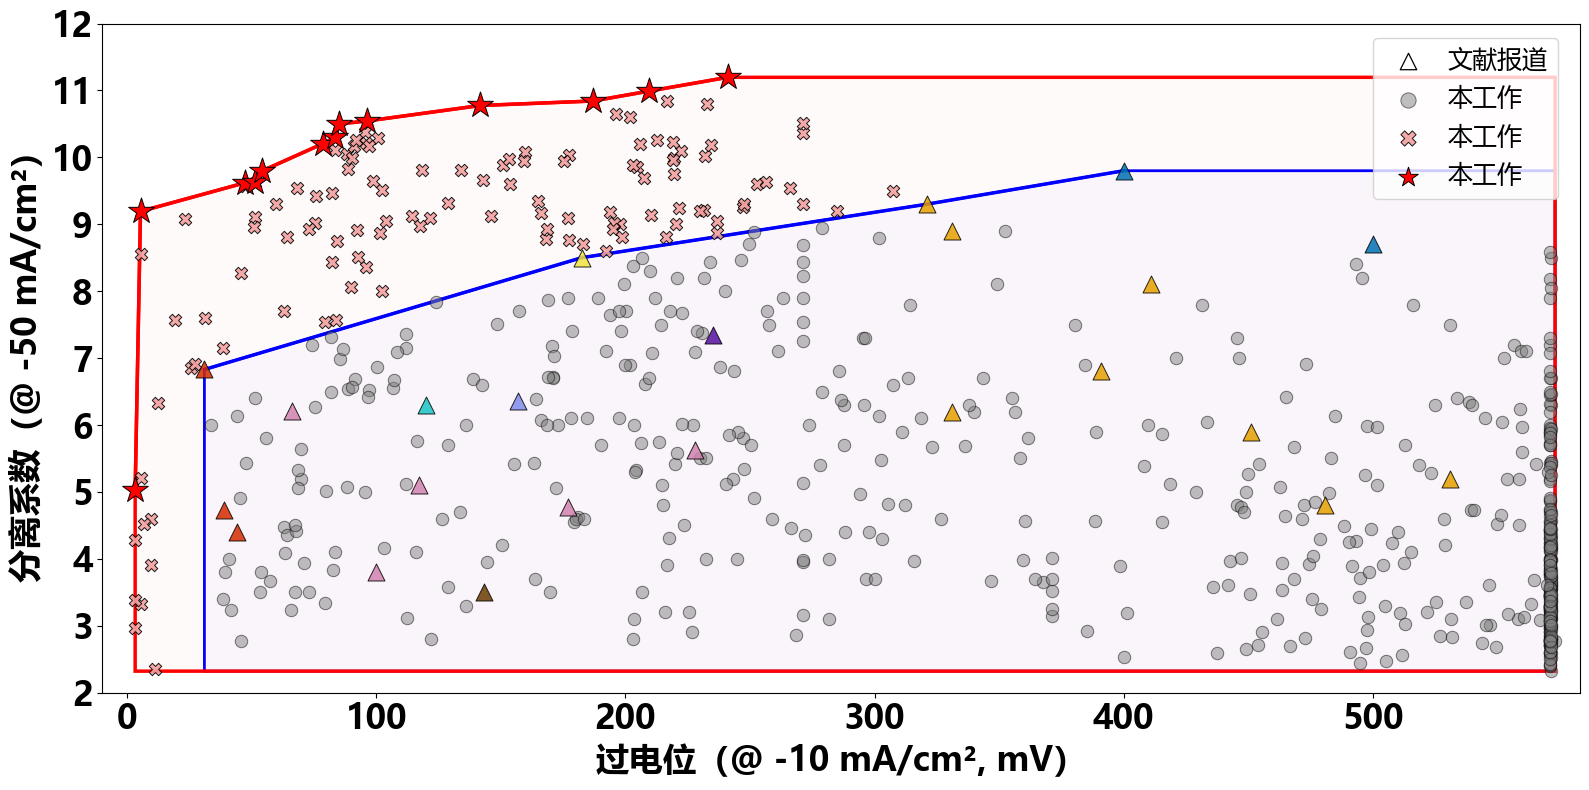

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon
from matplotlib.colors import to_rgba
from matplotlib.path import Path
import matplotlib as mpl
import re

# =========================
# 全局字体：微软雅黑
# =========================
mpl.rcParams["font.family"] = "sans-serif"
mpl.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "Arial"]
mpl.rcParams["axes.unicode_minus"] = False
mpl.rcParams["font.weight"] = "bold"
mpl.rcParams["axes.labelweight"] = "bold"
mpl.rcParams["path.simplify"] = False


def legend_name(lbl: str) -> str:
    lbl = str(lbl).strip()

    # Any literature reference -> same legend entry
    if re.match(r"^Reference\s+\d+$", lbl):
        return "文献报道"

    if lbl.lower() == "ni foam":
        return "Ni 泡沫"
    if lbl.lower() == "pt sheet":
        return "Pt 片"

    if lbl.lower() == "this work":
        return "本工作"

    return lbl


# =========================
# 1) Load your Excel
# =========================
path = "all_data_corrected_v2.xlsx"   # <- change if needed
raw = pd.read_excel(path, sheet_name="Sheet1")

# Make ALL column names strings so "24"/"26"... match
raw.columns = raw.columns.map(lambda c: str(c).strip())

# first row repeats headers ("Overpotential / Separation Coefficient"), drop it
df = raw.iloc[1:].copy()


def to_num(s):
    return pd.to_numeric(s, errors="coerce")


# =========================
# 2) Map each dataset to (x,y) columns
# =========================
datasets = [
    ("This work", "Unnamed: 1"),
    ("24", "Unnamed: 3"),
    ("26", "Unnamed: 5"),
    ("25", "Unnamed: 7"),
    ("27", "Unnamed: 9"),
    ("23", "Unnamed: 11"),
    ("20", "Unnamed: 13"),
    ("22", "Unnamed: 15"),
    ("Ni foam", "Unnamed: 17"),
    ("Pt sheet", "Unnamed: 19"),
]

rows = []
for x_col, y_col in datasets:
    if x_col not in df.columns or y_col not in df.columns:
        print(f"[警告] 缺少列: {x_col} / {y_col}")
        continue
    x = to_num(df[x_col])
    y = to_num(df[y_col])
    tmp = pd.DataFrame({"label": x_col, "x": x, "y": y}).dropna()
    rows.append(tmp)

data = pd.concat(rows, ignore_index=True)
data = data[np.isfinite(data["x"]) & np.isfinite(data["y"])].copy()
data = data.reset_index(drop=True)
data["pid"] = data.index

# Rename numeric refs -> "Reference 24" etc.
data["label"] = data["label"].astype(str).str.strip()
data["label"] = data["label"].apply(lambda s: f"Reference {s}" if s.isdigit() else s)

# =========================
# Apply transformation to "This work" overpotential (x-values)
# =========================
is_this = data["label"].str.strip().str.lower().eq("this work")
thisw = data[is_this].copy()

# Apply the transformations: 1. Minus, 2. Clip at 0, 3. Multiply by 1000
thisw["x"] = -(thisw["x"]) * 1000

# Replace the transformed "This work" data back into the main dataframe
data.loc[is_this, "x"] = thisw["x"]

# =========================
# 3) Pareto frontier (X lower better, Y higher better)
# =========================
def pareto_frontier_xy(pts: pd.DataFrame) -> pd.DataFrame:
    s = pts.sort_values(["x", "y"], ascending=[True, False]).reset_index(drop=True)
    best_y = -np.inf
    keep = []
    for _, r in s.iterrows():
        if r["y"] > best_y:
            keep.append(True)
            best_y = r["y"]
        else:
            keep.append(False)
    return s.loc[keep].reset_index(drop=True)


pre  = data[~is_this].copy()   # without This work
post = data.copy()             # with This work

front_pre  = pareto_frontier_xy(pre)
front_post = pareto_frontier_xy(post)

pareto_ids = set(front_post["pid"])

print("统计：",
      "pre 点数 =", len(pre),
      "| post 点数 =", len(post),
      "| front_pre =", len(front_pre),
      "| front_post =", len(front_post))

# =========================
# 4) Enclosure polygon (single outline, not stepwise)
# =========================
x_max = float(data["x"].max())
y_min = float(data["y"].min())

x_ref = x_max * 1.00 + 1e-6
y_ref = y_min - 1e-6


def enclosure_polygon(front: pd.DataFrame, x_ref: float, y_ref: float):
    f = front.sort_values("x", ascending=True).reset_index(drop=True)
    x0, y0 = float(f.loc[0, "x"]), float(f.loc[0, "y"])
    y_last = float(f.loc[len(f) - 1, "y"])
    pts = (
        [(x0, y_ref), (x0, y0)]
        + list(map(tuple, f[["x", "y"]].iloc[1:].to_numpy()))
        + [(x_ref, y_last), (x_ref, y_ref)]
    )
    return pts


poly_pre  = enclosure_polygon(front_pre,  x_ref, y_ref)
poly_post = enclosure_polygon(front_post, x_ref, y_ref)

# =========================
# 5) Plot
# =========================
fig, ax = plt.subplots(figsize=(16, 8))


def label_sort_key(lbl: str):
    lbl = str(lbl)
    if lbl.startswith("Reference "):
        try:
            return (0, int(lbl.split()[-1]))
        except:
            return (0, 10**9)
    if lbl == "Ni foam":  return (1, 0)
    if lbl == "Pt sheet": return (1, 1)
    return (2, lbl)


other_labels = sorted(pre["label"].unique(), key=label_sort_key)

palette = [
    "#0072B2",  # blue
    "#E69F00",  # orange
    "#5510A0",  # purple
    "#D52B00",  # vermillion
    "#F0E442",  # yellow
    "#D182AE",  # magenta
    "#818CEC",  # magenta
    "#6B3C03",  # brown
    "#19C7C7",  # cyan
]

markers = ["^"]  # literature markers

style = {}
for i, lbl in enumerate(other_labels):
    style[lbl] = dict(marker=markers[i % len(markers)],
                      color=palette[i % len(palette)])

# Enclosures
c_pre, c_post = "blue", "red"
ax.add_patch(Polygon(poly_pre, closed=True,
                     facecolor=to_rgba(c_pre, 0.02),
                     edgecolor=to_rgba(c_pre, 1.0),
                     linewidth=2.0,
                     zorder=1))
ax.add_patch(Polygon(poly_post, closed=True,
                     facecolor=to_rgba(c_post, 0.02),
                     edgecolor=to_rgba(c_post, 1.0),
                     linewidth=2.5,
                     zorder=1))

pre_plot = pre[~pre["pid"].isin(pareto_ids)]  # exclude ALL-DATA Pareto points

# 文献点：图中保持原来的彩色填充（黑边），但不进图例
for lbl in other_labels:
    sub = pre_plot[pre_plot["label"] == lbl]
    if sub.empty:
        continue
    ax.scatter(
        sub["x"], sub["y"],
        s=150, alpha=0.85,
        marker="^",
        facecolors=style[lbl]["color"],   # 彩色填充
        edgecolors="black", linewidths=0.7,
        label="_nolegend_",
        zorder=4,
    )

# 本工作：按是否在 pre 多边形内分类
thisw = data[is_this].copy()
thisw_plot = thisw[~thisw["pid"].isin(pareto_ids)]  # exclude ALL-DATA Pareto points

pre_path = Path(poly_pre)
inside_pre = pre_path.contains_points(thisw_plot[["x", "y"]].to_numpy(), radius=1e-9)

ax.scatter(thisw_plot.loc[inside_pre, "x"], thisw_plot.loc[inside_pre, "y"],
           marker="o", s=80, color="gray", alpha=0.5,
           edgecolors="black", linewidths=0.7,
           label="_nolegend_", zorder=3)

ax.scatter(thisw_plot.loc[~inside_pre, "x"], thisw_plot.loc[~inside_pre, "y"],
           marker="X", s=80, color="#F3A0A0", alpha=0.9,
           edgecolors="black", linewidths=0.7,
           label="_nolegend_", zorder=3)

# ALL-DATA Pareto 点：红星
ax.scatter(front_post["x"], front_post["y"],
           marker="*", s=380, color="red",
           edgecolors="black", linewidths=0.7,
           label="_nolegend_", zorder=10)

# Pareto front lines
ax.plot(front_post["x"], front_post["y"], color=c_post, linewidth=2.5, zorder=2)
ax.plot(front_pre["x"], front_pre["y"], color=c_pre, linewidth=2.5, zorder=2)

# 轴标签（中文）
ax.set_ylabel("分离系数（@ -50 mA/cm²）", fontsize=24, fontweight="bold")
ax.set_xlabel("过电位（@ -10 mA/cm², mV）", fontsize=24, fontweight="bold")

from matplotlib.ticker import MultipleLocator
ax.yaxis.set_major_locator(MultipleLocator(1))

ax.tick_params(axis="both", which="both", labelsize=24)
for t in ax.get_xticklabels() + ax.get_yticklabels():
    t.set_fontweight("bold")

ax.set_xlim(-10, x_ref + 10)
ax.set_ylim(2, 12)

# =========================
# 图例：文献报道（白心黑边三角） + 本工作（3 个标记）
# =========================
old_leg = ax.get_legend()
if old_leg is not None:
    old_leg.remove()

h_lit = ax.scatter([], [], marker="^", s=140,
                   facecolors="white", edgecolors="black",
                   linewidths=0.9, label="文献报道")

h_inside = ax.scatter([], [], marker="o", s=120,
                      color="gray", alpha=0.5,
                      edgecolors="black", linewidths=0.7,
                      label="本工作")

h_outside = ax.scatter([], [], marker="X", s=120,
                       color="#F3A0A0", alpha=0.9,
                       edgecolors="black", linewidths=0.7,
                       label="本工作")

h_pareto = ax.scatter([], [], marker="*", s=220,
                      color="red", alpha=1.0,
                      edgecolors="black", linewidths=0.7,
                      label="本工作")

leg = ax.legend(
    handles=[h_lit, h_inside, h_outside, h_pareto],
    loc="upper right",
    bbox_to_anchor=(0.99, 0.99),
    frameon=True,
    prop={"family": "Microsoft YaHei", "weight": "normal", "size": 18},
    handletextpad=0.6,
    borderaxespad=0.3,
)

plt.tight_layout()
fig.savefig("pareto_plot_v2_chinese.png", dpi=300)
plt.show()

